# Quick Intro to Aperture Photometry in Python

Based on Dr. Person's notebook, reworked for `NEO_001.fits`, the first frame of the Problem Set 2 asteroid sequence.

The target is the near-Earth asteroid 2026 QF3, observed for 120 s through the g' filter on the Wallace C14. The telescope tracked the *asteroid*, not the sky, so the asteroid is a round point source and every star in the field is smeared into a short trail. We will measure how much fainter the asteroid is than a nearby comparison star, and find that the trails change how we have to do it.

## Import Useful Packages

In [1]:
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from astropy.io import fits
import numpy as np

## Load Image and Get the Data into an Array

In [2]:
# Loads both the data and the file header.

hdu = fits.open("NEO_001.fits")

# Break the two parts up. The file stores unsigned 16-bit integers (ADU),
# so convert to float before doing any arithmetic with them.

data, header = hdu[0].data.astype(float), hdu[0].header

### View the header

In [3]:
header

SIMPLE  =                    T / conforms to FITS standard                      
BITPIX  =                   16 / array data type                                
NAXIS   =                    2 / number of array dimensions                     
NAXIS1  =                 1024                                                  
NAXIS2  =                 1024                                                  
EXTEND  =                    T                                                  
BSCALE  =                    1                                                  
BZERO   =                32768                                                  
BUNIT   = 'adu     '           / physical unit of the array values              
TELESCOP= 'Wallace C14 (Pier 3)' / MIT Wallace Astrophysical Observatory        
OBJECT  = '2026 QF3'           / target of the pointing                         
FILTER  = 'g''     '           / filter wheel position                          
EXPTIME =                120

A few header keywords are particularly important for this example. `TRACKING = 'NON-SIDEREAL'` tells us the mount followed the asteroid at `TRKRATE` arcsec/hr, so over the exposure each star drifts by `TRKRATE` × `EXPTIME`. Dividing by `PIXSCALE` turns that, and the seeing `FWHM`, into pixels.

In [4]:
exptime = header["EXPTIME"]                                # [s]
pixscale = header["PIXSCALE"]                              # [arcsec / pixel]
fwhm_px = header["FWHM"] / pixscale                        # [pixel]
trail_px = header["TRKRATE"] / 3600 * exptime / pixscale   # [pixel]

print(f"filter {header['FILTER']}, exposure {exptime} s")
print(f"seeing FWHM  = {fwhm_px:.1f} pixels")
print(f"star trails  = {trail_px:.1f} pixels long")

filter g', exposure 120.0 s
seeing FWHM  = 6.9 pixels
star trails  = 42.3 pixels long


## View the Data

In [5]:
print(data)

[[667. 655. 681. ... 671. 669. 691.]
 [655. 701. 685. ... 680. 653. 705.]
 [669. 652. 654. ... 683. 661. 687.]
 ...
 [672. 691. 679. ... 668. 682. 680.]
 [689. 682. 665. ... 684. 686. 674.]
 [665. 681. 697. ... 692. 691. 672.]]


## Display an Image

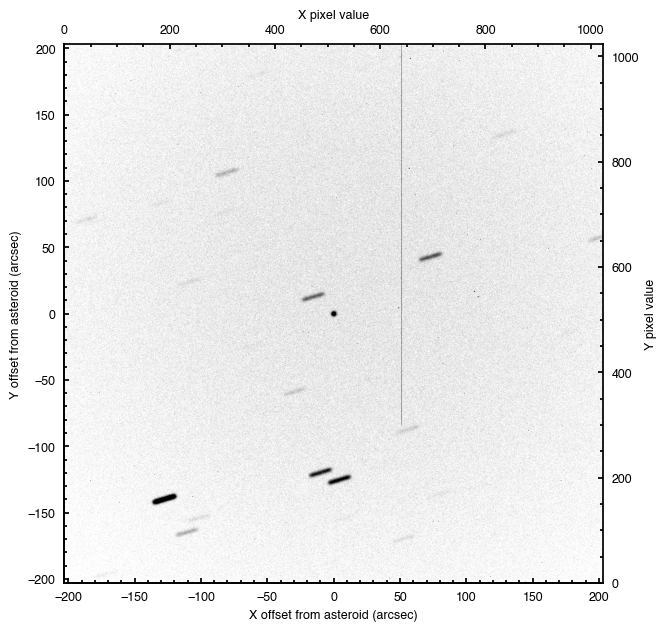

In [6]:
# Pixel coordinates of the image center, where the asteroid sits

ny, nx = data.shape
x0, y0 = (nx - 1) / 2, (ny - 1) / 2

def show_image(vmax=900, xlim=None, ylim=None, figsize=(7, 7), colorbar=False):
    """Display the frame in pixel coordinates, with offsets from the asteroid
    in arcseconds on the bottom and left axes. Limits are given in pixels."""
    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(data, cmap="binary", norm=LogNorm(vmin=680, vmax=vmax), origin="lower")
    if xlim is not None:
        ax.set_xlim(xlim)
    if ylim is not None:
        ax.set_ylim(ylim)

    # Top and right axes in pixels, for reading off source positions

    ax.xaxis.tick_top()
    ax.xaxis.set_label_position('top')
    ax.yaxis.tick_right()
    ax.yaxis.set_label_position('right')
    ax.set_xlabel('X pixel value')
    ax.set_ylabel('Y pixel value')

    # Bottom and left axes in arcseconds from the image center
    
    bottom = ax.secondary_xaxis('bottom', functions=(lambda x: (x - x0) * pixscale, lambda dx: dx / pixscale + x0))
    left = ax.secondary_yaxis('left', functions=(lambda y: (y - y0) * pixscale, lambda dy: dy / pixscale + y0))
    bottom.set_xlabel('X offset from asteroid (arcsec)')
    left.set_ylabel('Y offset from asteroid (arcsec)')

    if colorbar:
        cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.15)
        cbar.set_label('ADU')
    return ax

show_image()
plt.show()

The round dot at the center is the asteroid; every short dash is a star. The vertical line about 50 arcsec to the right, pixel column $x \approx 640$, is a hot column on the detector, not a source.

For a comparison star we'll use the trail just above and to the left of the asteroid, at about pixel (473, 543), about 20 arcsec away: it is close by and of similar brightness. Zoom in on the pair:

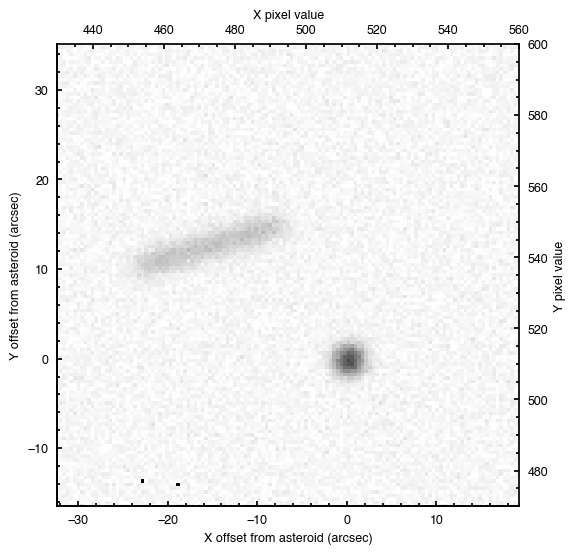

In [7]:
show_image(vmax=1500, xlim=(430, 560), ylim=(470, 600), figsize=(6, 6))
plt.show()

## Find Source Centers

In [8]:
# photutils has a lot of photometry reduction routines

from photutils.centroids import centroid_2dg, centroid_sources

# Start with an initial guess (from visual inspection or some other image/process).
# The search box has to hold the whole ~42 pixel trail of the comparison star,
# otherwise the centroid gets pulled toward whichever end of the trail is inside it.

x_center_comparison, y_center_comparison = centroid_sources(data, 473, 543, box_size=61,
                        centroid_func=centroid_2dg)

x_center_target, y_center_target = centroid_sources(data, 512, 511, box_size=21,
                        centroid_func=centroid_2dg)

print(x_center_comparison, y_center_comparison)
print(x_center_target, y_center_target)

[473.44460301] [543.09276623]
[512.15221111] [511.05318214]


## Define Source Centers and Aperture Radii

In [9]:
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

# coordinates of comparison star and target, respectively

coordinates = [(x_center_comparison[0], y_center_comparison[0]), (x_center_target[0], y_center_target[0])]

# define aperture radii

R1, R2, R3 = 10.0, 16.0, 22.0 #inspect the image to make sure these apertures are sensible

# create aperture objects

apertures = CircularAperture(coordinates, r=R1) #for total signal (star+background)
annulus_apertures = CircularAnnulus(coordinates, r_in=R2, r_out=R3) #for background
apers = [apertures, annulus_apertures]

### Plot image with apertures

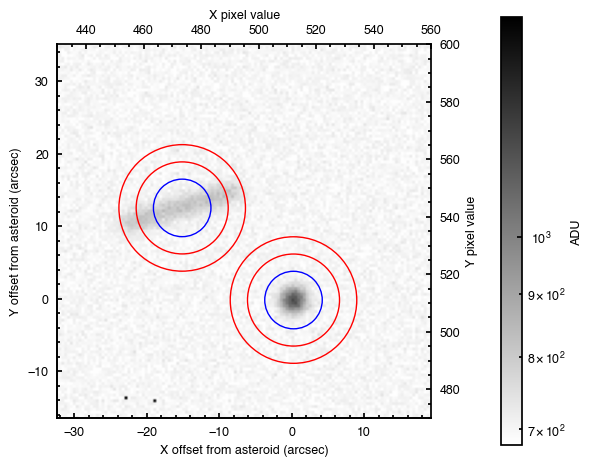

In [10]:
ax = show_image(vmax=1500, xlim=(430, 560), ylim=(470, 600), figsize=(6, 6), colorbar=True)
apertures.plot(ax=ax, color='b')
annulus_apertures.plot(ax=ax, color='r')
plt.show()

## Perform Aperture Photometry (Calculate Sums)

In [11]:
#perform aperture photometry

phot_table = aperture_photometry(data, apers)
print(phot_table)

 id      xcenter           ycenter         aperture_sum_0     aperture_sum_1  
--- ----------------- ------------------ ------------------ ------------------
  1 473.4446030119163   543.092766233683 235067.85489541854 508221.56028442417
  2  512.152211112401 511.05318213711405 244461.23026947066  501085.1834563856


## Subtract Background from Sources

In [12]:
# subtract background

#calculate mean background from outer annulus region

bkg_mean = phot_table["aperture_sum_1"]/annulus_apertures.area 

# scale to inner circular aperture

bkg_sum = bkg_mean*apertures.area 

final_sum = phot_table["aperture_sum_0"] - bkg_sum
phot_table["residual_aperture_sum"] = final_sum
phot_table

id,xcenter,ycenter,aperture_sum_0,aperture_sum_1,residual_aperture_sum
int64,float64,float64,float64,float64,float64
1,473.4446030119163,543.092766233683,235067.85489541854,508221.56028442417,12163.66178821493
2,512.152211112401,511.05318213711405,244461.23026947066,501085.1834563856,24687.026999126072


## Convert to Magnitudes

In [13]:
# magnitude of the target relative to the comparison star:
# positive means the target is fainter

deltaM = -2.5 * np.log10(final_sum[1] / final_sum[0])
print(round(deltaM, 2))

-0.77


That says the asteroid is about three quarters of a magnitude *brighter* than the star.

**But**, the blue circle on the star covers only the middle of the trail, so it misses much of the starlight. Worse, the red annulus, which is supposed to measure empty sky, lies across both ends of the trail, so starlight gets counted as "background" and subtracted. Both mistakes make the star look too faint, so the asteroid looks too bright.

A circle is the right shape for the round asteroid, but the wrong shape for a trailed star.

## Fix: An Aperture that Matches the Trail

The star's light is spread along a line of length $L$, then blurred by the seeing. An ellipse lying along the trail, with semi-major axis $a = L/2 + R_1$ and semi-minor axis $b = R_1$, covers the trail the way a circle of radius $R_1$ covers the round asteroid: it reaches $R_1$ past the trail in every direction. The background annulus is built the same way.

We need the trail's length and direction. Read the two ends of the trail off the zoomed image, then check the length against the prediction from the header.

In [14]:
# ends of the comparison star's trail, read off the zoomed image

x1, y1 = 453, 537
x2, y2 = 494, 549

trail_length = np.hypot(x2 - x1, y2 - y1)
trail_angle = np.arctan2(y2 - y1, x2 - x1)   # radians, counterclockwise from the +x axis

print(f"measured trail length = {trail_length:.1f} pixels (header predicts {trail_px:.1f})")
print(f"trail angle           = {np.degrees(trail_angle):.1f} degrees")

measured trail length = 42.7 pixels (header predicts 42.3)
trail angle           = 16.3 degrees


In [15]:
from photutils.aperture import EllipticalAperture, EllipticalAnnulus

comparison_aperture = EllipticalAperture(coordinates[0], a=trail_length/2 + R1, b=R1, theta=trail_angle)
comparison_annulus = EllipticalAnnulus(coordinates[0], a_in=trail_length/2 + R2, a_out=trail_length/2 + R3,
                                       b_in=R2, b_out=R3, theta=trail_angle)

#the asteroid keeps its circles
target_aperture = CircularAperture(coordinates[1], r=R1)
target_annulus = CircularAnnulus(coordinates[1], r_in=R2, r_out=R3)

### Plot image with the new apertures

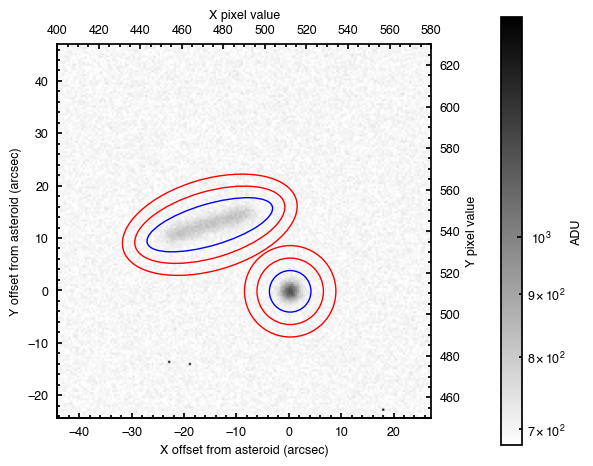

In [16]:
ax = show_image(vmax=1500, xlim=(400, 580), ylim=(450, 630), figsize=(6, 6), colorbar=True)
for aperture in [comparison_aperture, target_aperture]:
    aperture.plot(ax=ax, color='b')
for annulus in [comparison_annulus, target_annulus]:
    annulus.plot(ax=ax, color='r')
plt.show()

The blue ellipse now covers the whole trail, and the red annulus around it sits on empty sky. Check that neither annulus touches the other source.

We're about to repeat the same three steps (sum, background, subtract) with several apertures, so wrap them in a function.

In [17]:
def background_subtracted_sum(aperture, annulus):
    """Sum inside the aperture, minus the mean sky level from the annulus."""
    phot_table = aperture_photometry(data, [aperture, annulus])
    bkg_mean = phot_table["aperture_sum_1"][0] / annulus.area
    return phot_table["aperture_sum_0"][0] - bkg_mean * aperture.area

comparison_sum = background_subtracted_sum(comparison_aperture, comparison_annulus)
target_sum = background_subtracted_sum(target_aperture, target_annulus)

deltaM = -2.5 * np.log10(target_sum / comparison_sum)
print(f"comparison star: {comparison_sum:.0f} ADU")
print(f"asteroid:        {target_sum:.0f} ADU")
print(f"delta M = {deltaM:.2f}")

comparison star: 34497 ADU
asteroid:        24687 ADU
delta M = 0.36


Now the asteroid comes out *fainter* than the star, the opposite sign from before, and over a magnitude away from the circular-aperture answer.

## How Big Should the Aperture Be? Use a 'Curve of Growth'

$R_1 = 10$ pixels was a guess. Too small an aperture misses the wings of the seeing profile; too large an aperture adds sky noise and eventually runs into neighboring sources. A **curve of growth** measures the enclosed flux as the aperture grows, with the background annulus held fixed. The flux should rise steeply, then level off once the aperture holds essentially all the light.

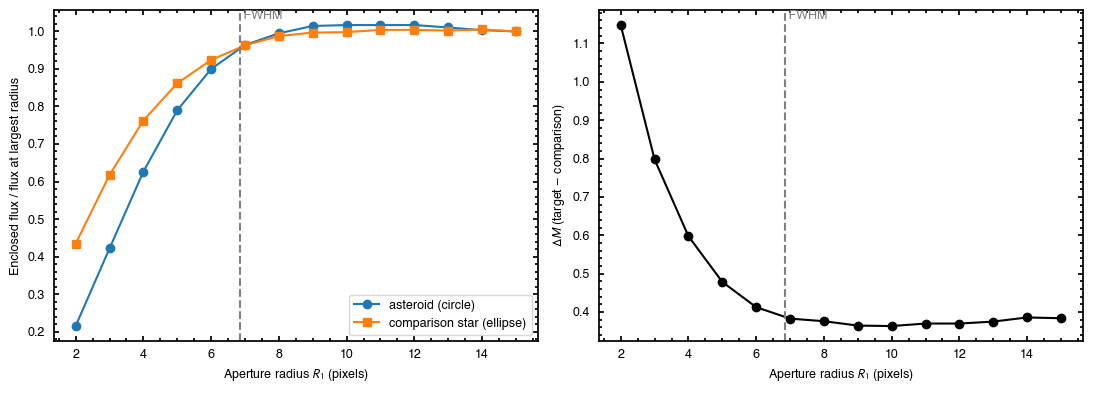

In [18]:
radii = np.arange(2, R2, 1.0)   #stay inside the annulus
comparison_sums, target_sums = [], []

for r in radii:
    comparison_sums.append(background_subtracted_sum(
        EllipticalAperture(coordinates[0], a=trail_length/2 + r, b=r, theta=trail_angle), comparison_annulus))
    target_sums.append(background_subtracted_sum(CircularAperture(coordinates[1], r=r), target_annulus))

comparison_sums, target_sums = np.array(comparison_sums), np.array(target_sums)
deltaMs = -2.5 * np.log10(target_sums / comparison_sums)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(radii, target_sums / target_sums[-1], 'o-', label='asteroid (circle)')
ax1.plot(radii, comparison_sums / comparison_sums[-1], 's-', label='comparison star (ellipse)')
ax1.set_xlabel('Aperture radius $R_1$ (pixels)')
ax1.set_ylabel('Enclosed flux / flux at largest radius')
ax1.legend()

ax2.plot(radii, deltaMs, 'o-', color='k')
ax2.set_xlabel('Aperture radius $R_1$ (pixels)')
ax2.set_ylabel(r'$\Delta M$ (target $-$ comparison)')

for ax in (ax1, ax2):
    ax.axvline(fwhm_px, color='gray', ls='--')
    ax.text(fwhm_px, ax.get_ylim()[1], ' FWHM', color='gray', va='top')
plt.tight_layout()
plt.show()

Both curves rise steeply out to about one FWHM ($\approx 7$ pixels) and are flat to within a few percent beyond it, so $R_1 = 10$ pixels ($\approx 1.5$ FWHM) holds essentially all of the light from both sources.

Note what happens to $\Delta M$ at small radii. For two *round* stars, a small aperture loses the same fraction of light from each, and the loss cancels in the ratio. Here the two sources have different shapes: a thin ellipse along a trail encloses a larger fraction of the star's light than a circle of the same $R_1$ encloses of the asteroid's, so the losses don't cancel and $\Delta M$ climbs steeply as $R_1$ shrinks. Once both apertures pass about one FWHM, $\Delta M$ settles to within a few hundredths of a magnitude, and the remaining wiggles are noise. When the target and comparison don't share a shape, use apertures big enough to hold all of the light.